### Playing in the mud  
(That's what my CS 180 professor called EDA)

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df_data = pd.read_csv('../data/raw/student_dropout_risk_2026.csv')
df_data

,person_id,age,gender,nationality,first_generation,disability_status,family_income_level,scholarship_holder,tuition_up_to_date,part_time_job,...,library_visits_per_month,lms_logins_per_week,extracurricular_activities,missed_deadlines,stress_level,mental_health_support,satisfaction_score,commute_time_mins,sleep_hours,dropout
0,1,23,Male,Brazil,0,0,Low,1,0,1,...,4,16.3,0,3,8,0,6,37,5.7,0
1,2,18,Other,USA,1,1,High,1,1,0,...,3,8.4,1,1,7,0,6,15,5.4,1
2,3,24,Other,USA,0,0,High,0,1,1,...,3,11.3,1,0,2,0,3,4,4.3,0
3,4,25,Female,USA,0,1,Middle,1,1,0,...,2,13.2,1,1,5,0,7,10,6.7,0
4,5,15,Female,Canada,0,0,Low,1,1,0,...,4,7.4,1,0,7,0,10,24,5.8,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,99996,25,Female,USA,0,0,Middle,1,1,1,...,10,6.2,0,0,4,0,6,11,5.9,0
99996,99997,24,Female,India,0,1,Middle,0,1,1,...,0,8.7,1,3,7,1,5,21,5.5,1
99997,99998,27,Female,USA,0,0,Middle,1,1,1,...,8,7.5,0,2,2,0,6,29,5.8,0
99998,99999,21,Male,UK,0,0,High,0,1,0,...,6,13.6,1,2,4,1,10,43,6.2,0


In [15]:
df_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 34 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   person_id                     100000 non-null  int64  
 1   age                           100000 non-null  int64  
 2   gender                        100000 non-null  str    
 3   nationality                   100000 non-null  str    
 4   first_generation              100000 non-null  int64  
 5   disability_status             100000 non-null  int64  
 6   family_income_level           100000 non-null  str    
 7   scholarship_holder            100000 non-null  int64  
 8   tuition_up_to_date            100000 non-null  int64  
 9   part_time_job                 100000 non-null  int64  
 10  weekly_work_hours             100000 non-null  int64  
 11  course_type                   100000 non-null  str    
 12  study_mode                    100000 non-null  str    
 

In [ ]:
"""
Ones to definetly remove:
- person_id
- nationality
"""
df_data.columns

Index(['person_id', 'age', 'gender', 'nationality', 'first_generation',
       'disability_status', 'family_income_level', 'scholarship_holder',
       'tuition_up_to_date', 'part_time_job', 'weekly_work_hours',
       'course_type', 'study_mode', 'semester', 'international_student',
       'admission_grade', 'previous_qualification_grade', 'units_enrolled',
       'units_passed', 'units_failed', 'gpa_semester_1', 'gpa_semester_2',
       'attendance_rate', 'assignments_submitted_rate',
       'library_visits_per_month', 'lms_logins_per_week',
       'extracurricular_activities', 'missed_deadlines', 'stress_level',
       'mental_health_support', 'satisfaction_score', 'commute_time_mins',
       'sleep_hours', 'dropout'],
      dtype='str')

In [4]:
df_data.describe()

,person_id,age,first_generation,disability_status,scholarship_holder,tuition_up_to_date,part_time_job,weekly_work_hours,semester,international_student,...,library_visits_per_month,lms_logins_per_week,extracurricular_activities,missed_deadlines,stress_level,mental_health_support,satisfaction_score,commute_time_mins,sleep_hours,dropout
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000,...,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,50000.500000,21.520840,0.420130,0.208770,0.589700,0.784860,0.481920,8.744620,3.617970,0.18094,...,4.366800,7.272294,0.594790,2.372140,6.448120,0.315560,6.318820,23.261360,6.556512,0.320040
std,28867.657797,3.399468,0.493582,0.406432,0.491891,0.410921,0.499676,10.232842,2.112763,0.38497,...,3.651653,3.936264,0.490935,2.587122,2.154185,0.464741,2.079066,23.932468,1.204067,0.466494
min,1.000000,15.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.00000,...,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,4.000000,0.000000
25%,25000.750000,19.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,2.000000,0.00000,...,2.000000,4.500000,0.000000,0.000000,5.000000,0.000000,5.000000,6.000000,5.700000,0.000000
50%,50000.500000,21.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,3.000000,0.00000,...,3.000000,7.100000,1.000000,2.000000,7.000000,0.000000,6.000000,16.000000,6.500000,0.000000
75%,75000.250000,24.000000,1.000000,0.000000,1.000000,1.000000,1.000000,18.000000,5.000000,0.00000,...,6.000000,9.800000,1.000000,3.000000,8.000000,1.000000,8.000000,33.000000,7.400000,1.000000
max,100000.000000,30.000000,1.000000,1.000000,1.000000,1.000000,1.000000,40.000000,8.000000,1.00000,...,30.000000,29.600000,1.000000,20.000000,10.000000,1.000000,10.000000,120.000000,10.000000,1.000000


In [34]:
# gender: 2 categories -> single 0/1 column
codes, uniques = pd.factorize(df_data["gender"])
df_data["gender"] = codes
print("gender mapping:", dict(enumerate(uniques)))

# course_type (5) and study_mode (3): one-hot, dropping one level each
df_encoded = pd.get_dummies(df_data, columns=["course_type", "study_mode", "family_income_level"], drop_first=True, dtype=int)
df_encoded.columns

df_encoded.to_csv("../data/processed/encoded_student_risk.csv", index=False)

gender mapping: {0: 0, 1: 1, 2: 2}


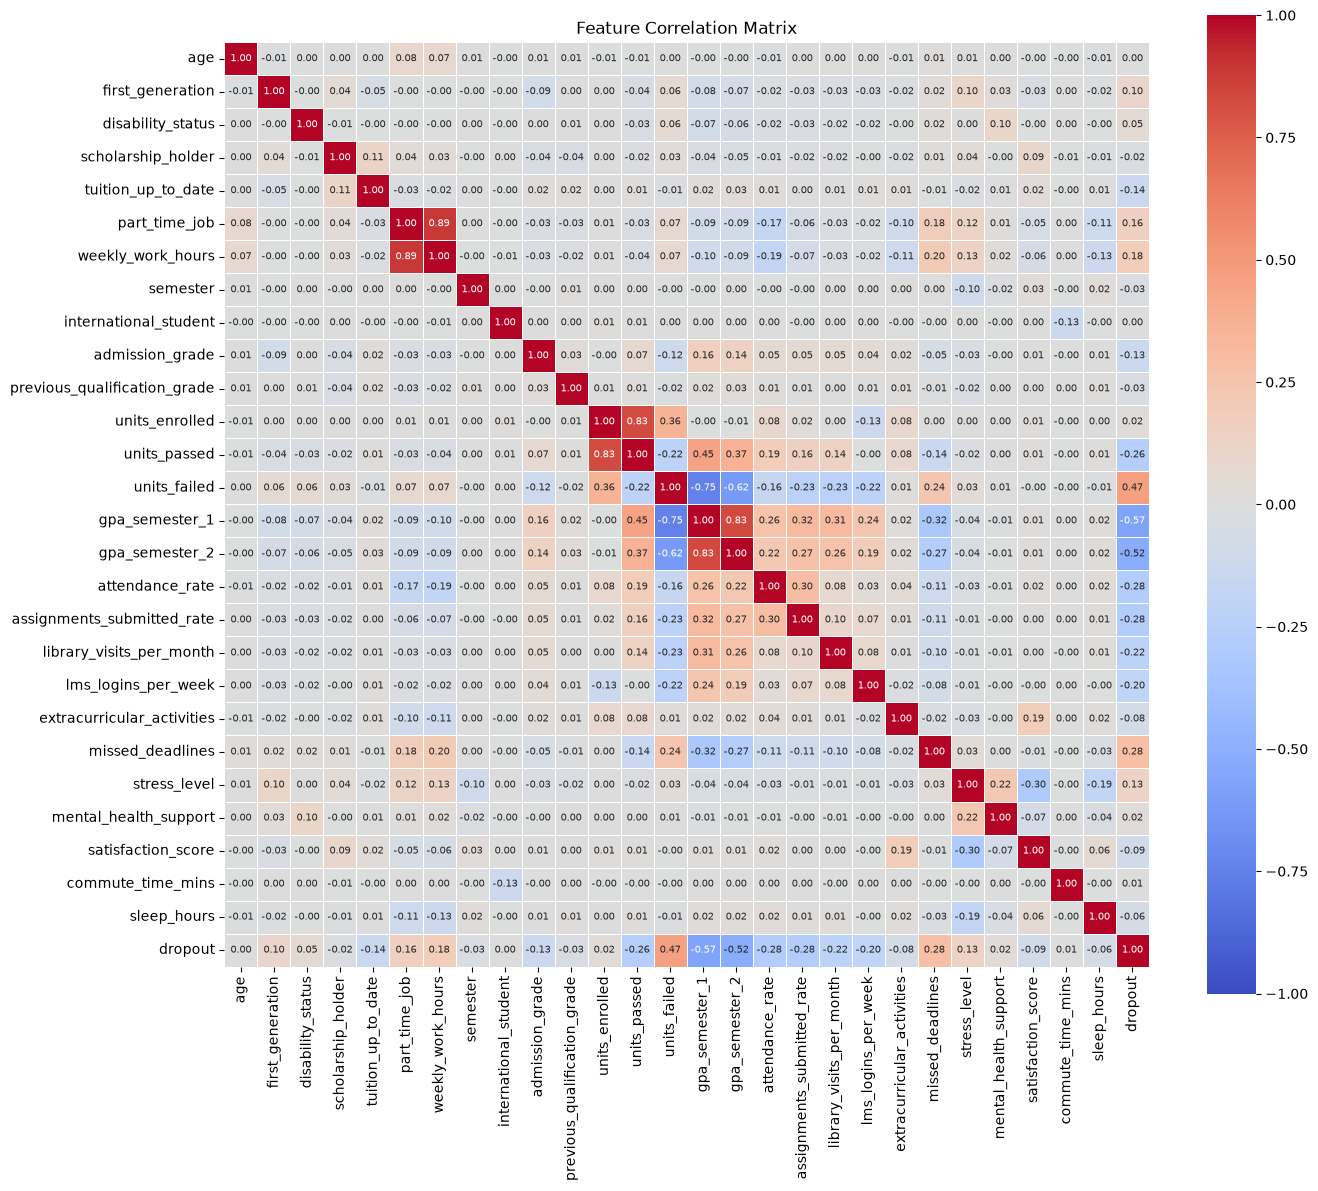

In [10]:

# Drop the identifier and nationality, keep only numeric columns
corr_df = df_data.drop(columns=["person_id", "nationality"], errors="ignore")
corr = corr_df.select_dtypes(include="number").corr()

plt.figure(figsize=(14, 12))
sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    vmin=-1, vmax=1,
    annot=True, fmt=".2f", annot_kws={"size": 7},
    square=True,
    linewidths=0.5,
)
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()


Columns with most correlations:
- Units passed -> units enrolled (positive correlation)
- Units failed -> GPA semester 1 and 2 (negative correlation)
- gpa semester 1 -> gpa semester 2 (positive correlation)
- units_failed -> dropout (positive correlation)
- gpa -> dropout (negative correlation)

In [33]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SequentialFeatureSelector

X = df_encoded.drop(columns=["person_id", "nationality", "dropout"])  # adjust target name
y = df_encoded["dropout"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

sfs = SequentialFeatureSelector(
    model,
    direction="backward",
    n_features_to_select="auto",
    tol=0.001,           # stop when removing a feature costs > 0.001 AUC
    scoring="roc_auc",
    cv=5,
    n_jobs=-1,
)
sfs.fit(X_train, y_train)

selected = X_train.columns[sfs.get_support()].tolist()
print(f"Kept {len(selected)} features:", selected)
print("Dropped:", [c for c in X_train.columns if c not in selected])


Kept 35 features: ['age', 'gender', 'first_generation', 'disability_status', 'scholarship_holder', 'tuition_up_to_date', 'part_time_job', 'weekly_work_hours', 'semester', 'admission_grade', 'previous_qualification_grade', 'units_enrolled', 'units_passed', 'units_failed', 'gpa_semester_1', 'gpa_semester_2', 'attendance_rate', 'assignments_submitted_rate', 'library_visits_per_month', 'lms_logins_per_week', 'extracurricular_activities', 'missed_deadlines', 'stress_level', 'mental_health_support', 'satisfaction_score', 'commute_time_mins', 'sleep_hours', 'course_type_Business', 'course_type_Health Sciences', 'course_type_Law & Social Sciences', 'course_type_STEM', 'study_mode_Online', 'study_mode_Part-time', 'family_income_level_Low', 'family_income_level_Middle']
Dropped: ['international_student']


Apparently, with backward selection it kept everything except for internationsl student...